
# Exploratory Data Analysis (EDA) on Students Performance

### CodeAlpha Data Analytics Internship - Task 1

**Notebook By:** Ranjana Singh

**Dataset:** Students Performance in Exams

**Source:** Kaggle – Students Performance in Exams

**Dataset Author:** spscientist

**License:** Please refer to the license displayed on the Kaggle dataset page before redistributing the dataset.
## Introduction

This notebook presents an Exploratory Data Analysis (EDA) of the Students Performance in Exams dataset. It examines students' Mathematics, Reading, and Writing scores to identify performance patterns, compare student groups, and discover meaningful insights through statistical analysis and visualizations.


In [2]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'): 
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/spscientist/students-performance-in-exams/StudentsPerformance.csv


### Dataset Path

- **os**: Python module for working with files and folders.
- **os.walk()**: searches the Kaggle input directory for available files.

The output shows the path of **StudentsPerformance.csv**, which is used to load the data in the next step.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    '/kaggle/input/datasets/spscientist/students-performance-in-exams/StudentsPerformance.csv'
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


### Libraries Used

- **Pandas**: data loading, cleaning and analysis.
- **NumPy**: numerical operations.
- **Matplotlib**: basic charts (bar, line, histogram).
- **Seaborn**: statistical charts like heatmaps and count plots.

The dataset is loaded into a DataFrame called `df`.

In [4]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### Dataset Preview

- Each row represents one student, and each column is a feature.
- Columns include **gender**, **race/ethnicity**, **parental level of education**, **lunch**, **test preparation course**, and the **math**, **reading** and **writing** scores.
- Scores are numeric, and the other columns are categorical (text).

In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1000
Number of columns: 8


## Dataset Size

- The dataset has **1000 rows** (students) and **8 columns** (features).
- This is a good size for exploratory analysis and comparing student groups.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


### Data Types and Structure

- 1000 entries and 8 columns, with **no null values**.
- 5 columns are text (object) and 3 score columns are integers.

In [7]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


### Summary Statistics

- Average scores: **Math 66.1**, **Reading 69.2**, **Writing 68.1**.
- Math has the lowest minimum (0) and the lowest average of the three subjects.
- All three subjects reach a maximum of 100.

In [8]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

### Missing Values

- Every column shows 0, so there are **no missing values**.
- No data cleaning is needed.

In [9]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


### Duplicate Records

- The dataset has **0 duplicate rows**, so every record is unique.

In [10]:
print("Gender Distribution:")
print(df['gender'].value_counts())

print("\nParental Education Distribution:")
print(df['parental level of education'].value_counts())

print("\nTest Preparation Distribution:")
print(df['test preparation course'].value_counts())

Gender Distribution:
gender
female    518
male      482
Name: count, dtype: int64

Parental Education Distribution:
parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

Test Preparation Distribution:
test preparation course
none         642
completed    358
Name: count, dtype: int64


### Category Distributions

- **Gender:** 518 female and 482 male, a fairly balanced split.
- **Parental education:** "some college" (226) and "associate's degree" (222) are most common. Master's degree is the least common (59).
- **Test preparation:** 642 students did not complete the course and 358 did.

In [11]:
gender_performance = df.groupby('gender')[
    ['math score', 'reading score', 'writing score']
].mean()

print(gender_performance)

        math score  reading score  writing score
gender                                          
female   63.633205      72.608108      72.467181
male     68.728216      65.473029      63.311203


### Average Scores by Gender

- Male students score higher in **Math** (68.7 vs 63.6).
- Female students score higher in **Reading** (72.6 vs 65.5) and **Writing** (72.5 vs 63.3).

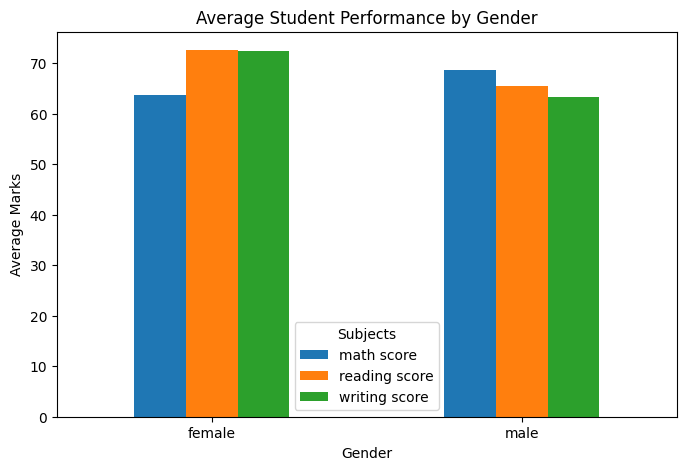

In [12]:
gender_performance.plot(
    kind='bar',
    figsize=(8,5),
    title='Average Student Performance by Gender'
)

plt.xlabel('Gender')
plt.ylabel('Average Marks')
plt.xticks(rotation=0)
plt.legend(title='Subjects')
plt.show()

### Gender Performance Chart

- The bar chart shows the same pattern: males lead in Math, and females lead in Reading and Writing.
  

In [13]:
prep_performance = df.groupby('test preparation course')[
    ['math score', 'reading score', 'writing score']
].mean()

print(prep_performance)

                         math score  reading score  writing score
test preparation course                                          
completed                 69.695531      73.893855      74.418994
none                      64.077882      66.534268      64.504673


### Average Scores by Test Preparation

- Students who **completed** the course score higher in all three subjects.
- The largest gap is in Writing (74.4 vs 64.5).

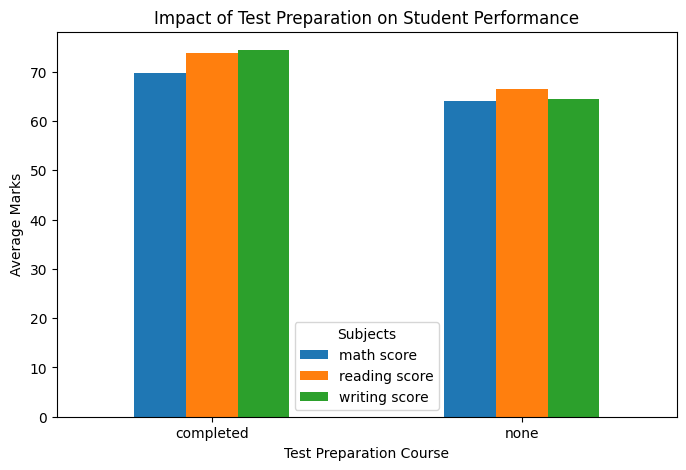

In [14]:
prep_performance.plot(
    kind='bar',
    figsize=(8,5),
    title='Impact of Test Preparation on Student Performance'
)

plt.xlabel('Test Preparation Course')
plt.ylabel('Average Marks')
plt.xticks(rotation=0)
plt.legend(title='Subjects')
plt.show()

### Test Preparation Chart

- Completing the preparation course is associated with higher scores in every subject.

In [15]:
parent_education = df.groupby('parental level of education')[
    ['math score', 'reading score', 'writing score']
].mean()

print(parent_education)

                             math score  reading score  writing score
parental level of education                                          
associate's degree            67.882883      70.927928      69.896396
bachelor's degree             69.389831      73.000000      73.381356
high school                   62.137755      64.704082      62.448980
master's degree               69.745763      75.372881      75.677966
some college                  67.128319      69.460177      68.840708
some high school              63.497207      66.938547      64.888268


### Average Scores by Parental Education

- Students whose parents hold a **master's** or **bachelor's** degree score highest overall.
- Students whose parents have only **high school** or **some high school** education score lowest.

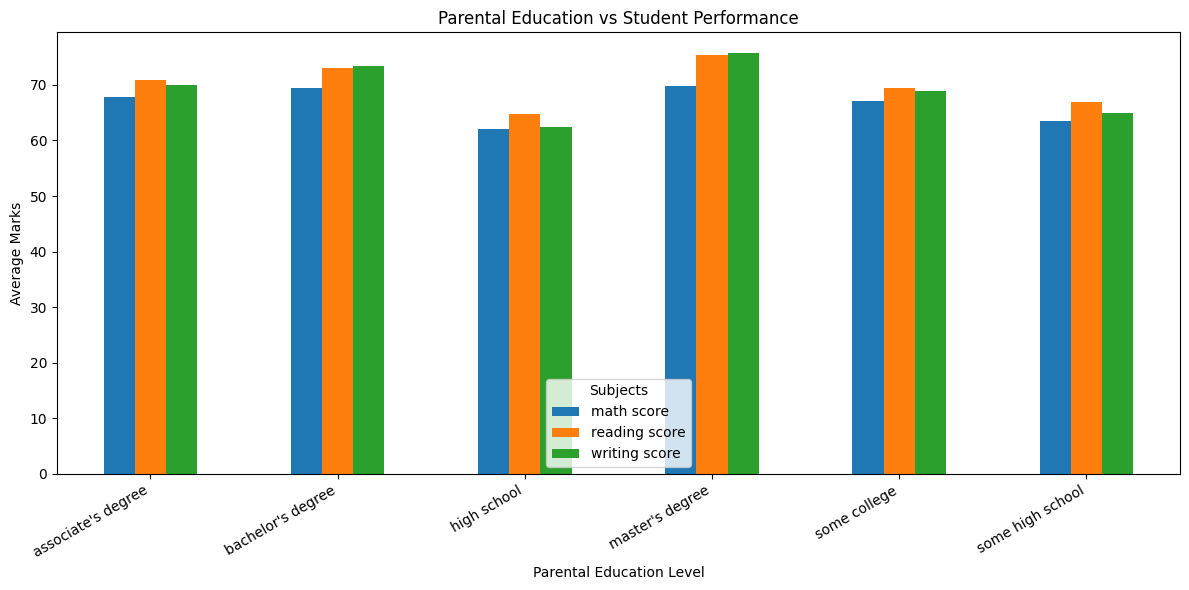

In [16]:
parent_education.plot(
    kind='bar',
    figsize=(12,6),
    title='Parental Education vs Student Performance'
)

plt.xlabel('Parental Education Level')
plt.ylabel('Average Marks')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Subjects')
plt.tight_layout()
plt.show()

### Parental Education Chart

- Scores generally rise with the parents' education level.
- This is an association, not proof of cause.

In [17]:
lunch_performance = df.groupby('lunch')[
    ['math score', 'reading score', 'writing score']
].mean()

print(lunch_performance)

              math score  reading score  writing score
lunch                                                 
free/reduced   58.921127      64.653521      63.022535
standard       70.034109      71.654264      70.823256


### Average Scores by Lunch Type

- Students with **standard** lunch score higher in all subjects.
- The biggest gap is in Math (70.0 vs 58.9).

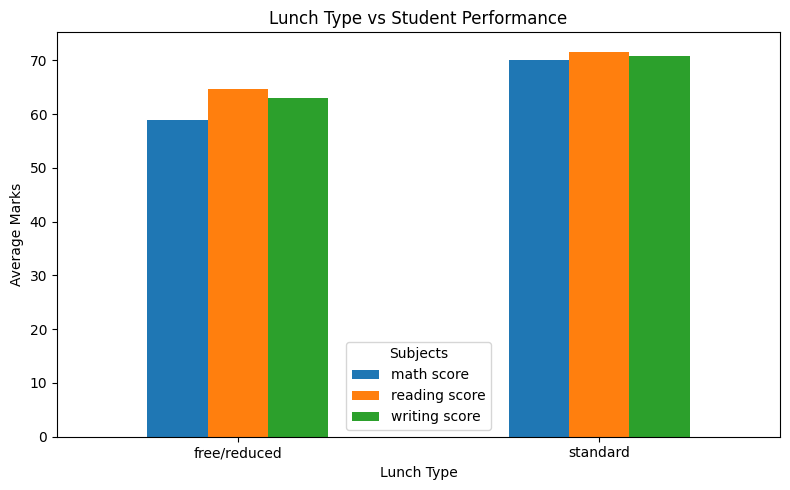

In [18]:
lunch_performance.plot(
    kind='bar',
    figsize=(8,5),
    title='Lunch Type vs Student Performance'
)

plt.xlabel('Lunch Type')
plt.ylabel('Average Marks')
plt.xticks(rotation=0)
plt.legend(title='Subjects')
plt.tight_layout()
plt.show()

### Lunch Type Chart

- Students on free/reduced lunch score noticeably lower in every subject.
- Lunch type may reflect differences in family background.

In [19]:
correlation = df[
    ['math score', 'reading score', 'writing score']
].corr()

print(correlation)

               math score  reading score  writing score
math score       1.000000       0.817580       0.802642
reading score    0.817580       1.000000       0.954598
writing score    0.802642       0.954598       1.000000


### Correlation Between Scores

- Reading and Writing are very strongly correlated (**0.95**).
- Math is strongly correlated with Reading (0.82) and Writing (0.80).

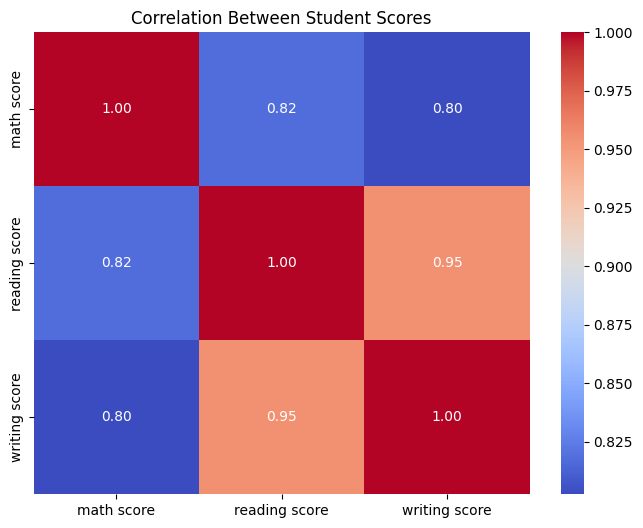

In [20]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Student Scores')
plt.show()

### Correlation Heatmap

- The heatmap shows all three scores are positively related.
- Students who do well in one subject tend to do well in the others.

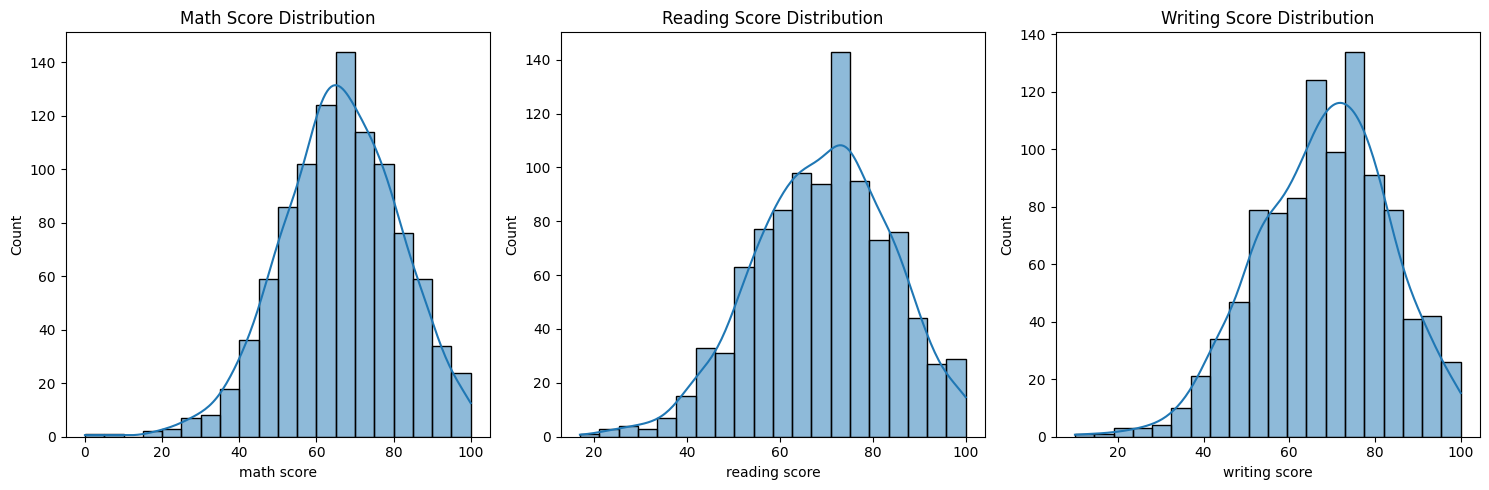

In [21]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.histplot(df['math score'], bins=20, kde=True)
plt.title('Math Score Distribution')

plt.subplot(1, 3, 2)
sns.histplot(df['reading score'], bins=20, kde=True)
plt.title('Reading Score Distribution')

plt.subplot(1, 3, 3)
sns.histplot(df['writing score'], bins=20, kde=True)
plt.title('Writing Score Distribution')

plt.tight_layout()
plt.show()

### Score Distributions

- All three subjects are roughly **bell-shaped**, centred around 60 to 75.
- Few students score at the very low or very high ends.

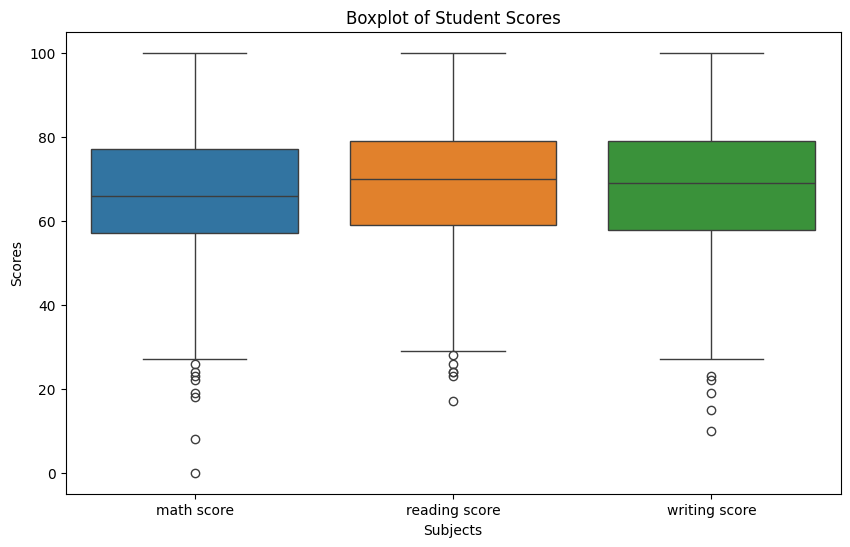

In [22]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df[['math score', 'reading score', 'writing score']])

plt.title('Boxplot of Student Scores')
plt.xlabel('Subjects')
plt.ylabel('Scores')

plt.show()

### Boxplot of Scores

- The boxes show the median and spread for each subject.
- Math has a slightly lower median than Reading and Writing.
- Points beyond the whiskers are potential outliers.

In [23]:
subjects = ['math score', 'reading score', 'writing score']

for subject in subjects:
    Q1 = df[subject].quantile(0.25)
    Q3 = df[subject].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[subject] < lower_limit) |
        (df[subject] > upper_limit)
    ]

    print(subject)
    print("Number of outliers:", len(outliers))
    print("----------------------")

math score
Number of outliers: 8
----------------------
reading score
Number of outliers: 6
----------------------
writing score
Number of outliers: 5
----------------------


### Outlier Detection (IQR Method)

- Outliers found: **Math 8**, **Reading 6**, **Writing 5**.
- These are a small share of 1000 students, so they were kept in the analysis.

In [24]:
df['average_score'] = (
    df['math score'] +
    df['reading score'] +
    df['writing score']
) / 3

df[['math score', 'reading score', 'writing score', 'average_score']].head()

,math score,reading score,writing score,average_score
0,72,72,74,72.666667
1,69,90,88,82.333333
2,90,95,93,92.666667
3,47,57,44,49.333333
4,76,78,75,76.333333


### Average Score Feature

- Created a new column, **average_score**, as the mean of the three subject scores.

In [25]:
print("Overall Average Score:", df['average_score'].mean())

print("Highest Average Score:", df['average_score'].max())

print("Lowest Average Score:", df['average_score'].min())

Overall Average Score: 67.77066666666666
Highest Average Score: 100.0
Lowest Average Score: 9.0


### Overall Average Performance

- The overall average score is about **67.8**.
- The highest and lowest average scores are shown in the output above.

In [26]:
def categorize_performance(score):
    if score >= 80:
        return 'Excellent'
    elif score >= 60:
        return 'Good'
    elif score >= 40:
        return 'Average'
    else:
        return 'Needs Improvement'

df['performance'] = df['average_score'].apply(categorize_performance)

print(df['performance'].value_counts())

performance
Good                 517
Average              255
Excellent            198
Needs Improvement     30
Name: count, dtype: int64


### Performance Categories

- Students are grouped by average score: Excellent (80+), Good (60-79), Average (40-59) and Needs Improvement (below 40).
- **Good:** 517, **Average:** 255, **Excellent:** 198, **Needs Improvement:** 30.

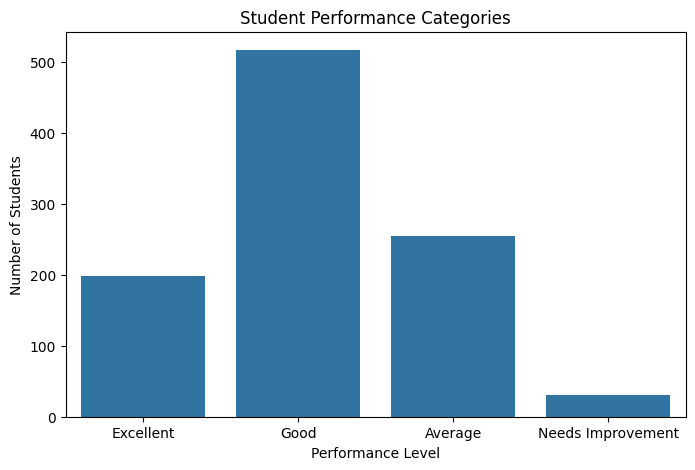

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='performance',
    order=['Excellent', 'Good', 'Average', 'Needs Improvement']
)

plt.title('Student Performance Categories')
plt.xlabel('Performance Level')
plt.ylabel('Number of Students')
plt.show()

### Performance Category Chart

- Most students fall in the **Good** category, and very few need improvement.

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/kaggle/input/datasets/spscientist/students-performance-in-exams/StudentsPerformance.csv')

print(df.head())
print(df.shape)

   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  
(1000, 8)


### Data Reload and Preview

- Reloads the dataset and confirms its shape: **1000 rows and 8 columns**.

In [32]:
df['average_score'] = (
    df['math score'] +
    df['reading score'] +
    df['writing score']
) / 3

def categorize_performance(score):
    if score >= 80:
        return 'Excellent'
    elif score >= 60:
        return 'Good'
    elif score >= 40:
        return 'Average'
    else:
        return 'Needs Improvement'

df['performance'] = df['average_score'].apply(categorize_performance)

In [33]:
df[['average_score', 'performance']].head()

,average_score,performance
0,72.666667,Good
1,82.333333,Excellent
2,92.666667,Excellent
3,49.333333,Average
4,76.333333,Good


### Performance Category Check

- Recomputes the average score and performance category, then previews them.

In [34]:
print("========== FINAL DATA INSIGHTS ==========")

print("\n1. Total Students:", len(df))

print("\n2. Average Subject Scores:")
print(df[['math score', 'reading score', 'writing score']].mean())

print("\n3. Highest Average Score:")
print(df['average_score'].max())

print("\n4. Lowest Average Score:")
print(df['average_score'].min())

print("\n5. Performance Distribution:")
print(df['performance'].value_counts())

print("\n6. Average Scores by Gender:")
print(df.groupby('gender')[['math score', 'reading score', 'writing score']].mean())

print("\n7. Average Scores by Test Preparation:")
print(df.groupby('test preparation course')[['math score', 'reading score', 'writing score']].mean())

========== FINAL DATA INSIGHTS ==========

1. Total Students: 1000

2. Average Subject Scores:
math score       66.089
reading score    69.169
writing score    68.054
dtype: float64

3. Highest Average Score:
100.0

4. Lowest Average Score:
9.0

5. Performance Distribution:
performance
Good                 517
Average              255
Excellent            198
Needs Improvement     30
Name: count, dtype: int64

6. Average Scores by Gender:
        math score  reading score  writing score
gender                                          
female   63.633205      72.608108      72.467181
male     68.728216      65.473029      63.311203

7. Average Scores by Test Preparation:
                         math score  reading score  writing score
test preparation course                                          
completed                 69.695531      73.893855      74.418994
none                      64.077882      66.534268      64.504673


### Final Data Insights

- Summary of the key results: total students, average scores, performance distribution, and group comparisons by gender and test preparation.

## Final Conclusion

EDA was performed on the Students Performance in Exams dataset (1,000 records, no missing values or duplicates).

**Key findings:**
- Males scored higher in Math, while females scored higher in Reading and Writing.
- Students who completed test preparation scored higher in all subjects.
- Higher parental education and standard lunch were associated with higher scores.
- Reading and Writing are very strongly correlated (0.95).
- Most students (517) fall in the "Good" category, and only 30 need improvement.
- Few outliers were found, so no records were removed.

**Tools used:** Pandas, NumPy, Matplotlib and Seaborn.